In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import folium
from pathlib import Path

In [2]:
DATA_CLEAN = Path("../data/processed")
MAPS_DIR = Path("../visualizations")
MAPS_DIR.mkdir(parents=True, exist_ok=True)

sf_sb79_parcels_gdf = gpd.read_parquet(DATA_CLEAN / "sf_sb79_parcels_scaled.parquet")
print("SB 79 lots:", len(sf_sb79_parcels_gdf), "| CRS:", sf_sb79_parcels_gdf.crs.name)
print("acres:", round(sf_sb79_parcels_gdf["acres"].sum()))

SB 79 lots: 128637 | CRS: NAD83 / California zone 3 (ftUS)
acres: 21535


In [3]:
SCALE_ORDER = [0, 1, 2, 3, 4, 5, 6]
SCALE_LABELS = {
    0: "0  housing not allowed",
    1: "1  under 30 du/ac",
    2: "2  30-79 du/ac",
    3: "3  80-99 du/ac",
    4: "4  100-119 du/ac",
    5: "5  120-159 du/ac",
    6: "6  160+ du/ac",
}
#one blue per score, light to dark (same Blues family as the Oakland charts)
blues = plt.cm.Blues(np.linspace(0.2, 1.0, 6))
SCALE_COLORS = {0: "#d9d9d9"}
for score, color in zip(range(1, 7), blues):
    SCALE_COLORS[score] = plt.matplotlib.colors.to_hex(color)
NOT_SCORED_COLOR = "#8a8a8a"

#same colors as the Oakland zone-category charts
TYPE_COLORS = {
    "mixed_use": "#8b5cf6", "residential": "#06b6d4", "commercial": "#f97316",
    "industrial": "#dc2626", "park": "#d9f99d", "civic": "#14b8a6", "unknown": "#9ca3af",
}

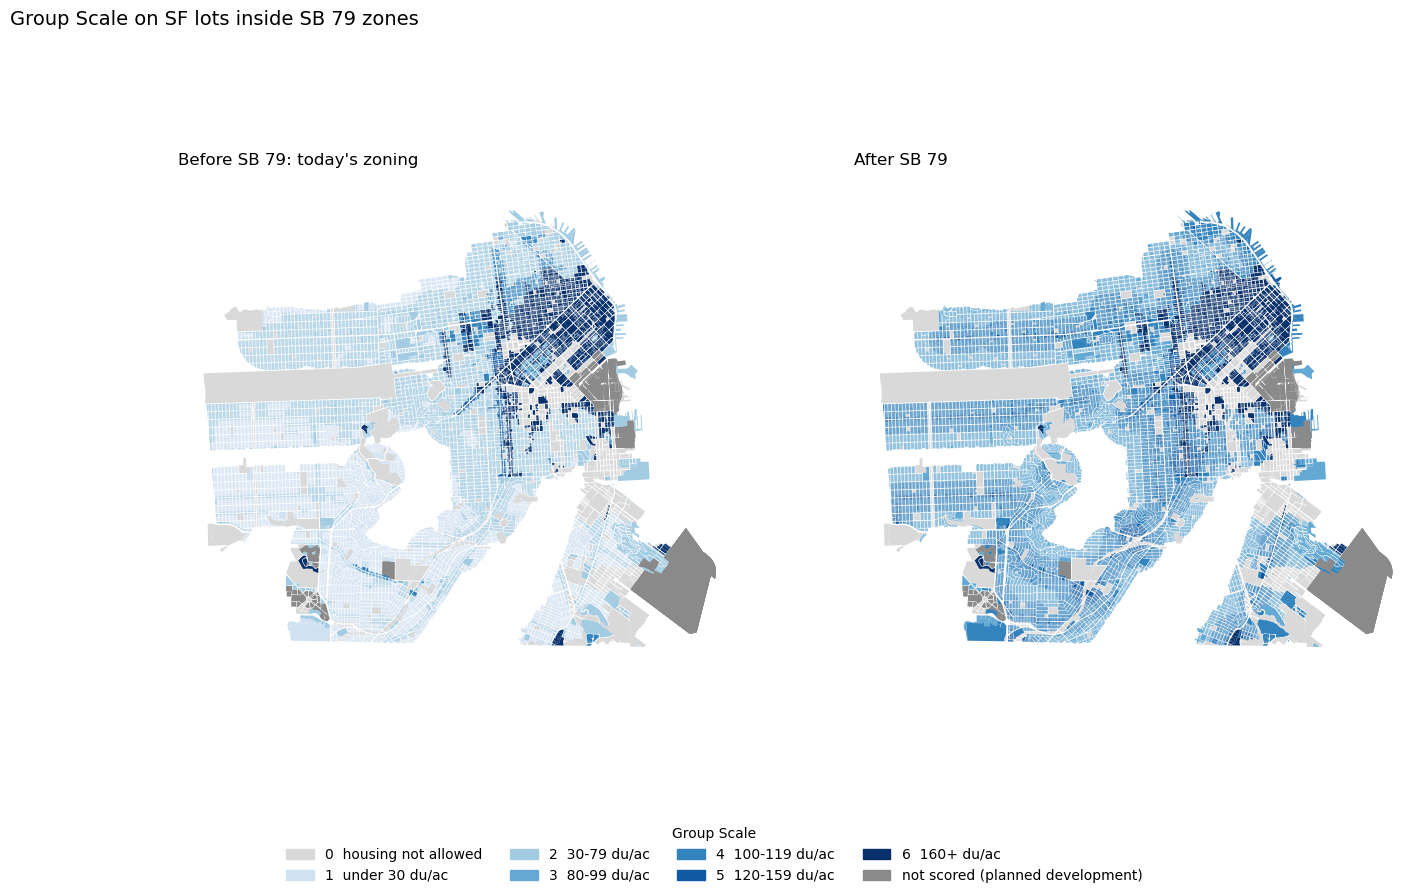

In [4]:
def plot_scale(ax, gdf, column, title):
    #one layer per score, so every score gets its own color and legend entry
    for score in SCALE_ORDER:
        layer = gdf[gdf[column] == score]
        if len(layer) > 0:
            layer.plot(ax=ax, color=SCALE_COLORS[score], linewidth=0)
    gdf[gdf[column].isna()].plot(ax=ax, color=NOT_SCORED_COLOR, linewidth=0)
    ax.set_title(title, loc="left")
    ax.set_axis_off()

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
plot_scale(axes[0], sf_sb79_parcels_gdf, "scale_before", "Before SB 79: today's zoning")
plot_scale(axes[1], sf_sb79_parcels_gdf, "scale_after", "After SB 79")

#one shared legend
handles = [plt.matplotlib.patches.Patch(color=SCALE_COLORS[s], label=SCALE_LABELS[s]) for s in SCALE_ORDER]
handles.append(plt.matplotlib.patches.Patch(color=NOT_SCORED_COLOR, label="not scored"))
fig.legend(handles=handles, title="Group Scale", loc="lower center", ncol=4, frameon=False)
fig.suptitle("Group Scale on SF lots inside SB 79 zones", x=0.02, ha="left", fontsize=14)
plt.subplots_adjust(bottom=0.15)
plt.savefig(MAPS_DIR / "sf_scale_before_after_map.png", dpi=150, bbox_inches="tight")
plt.show()

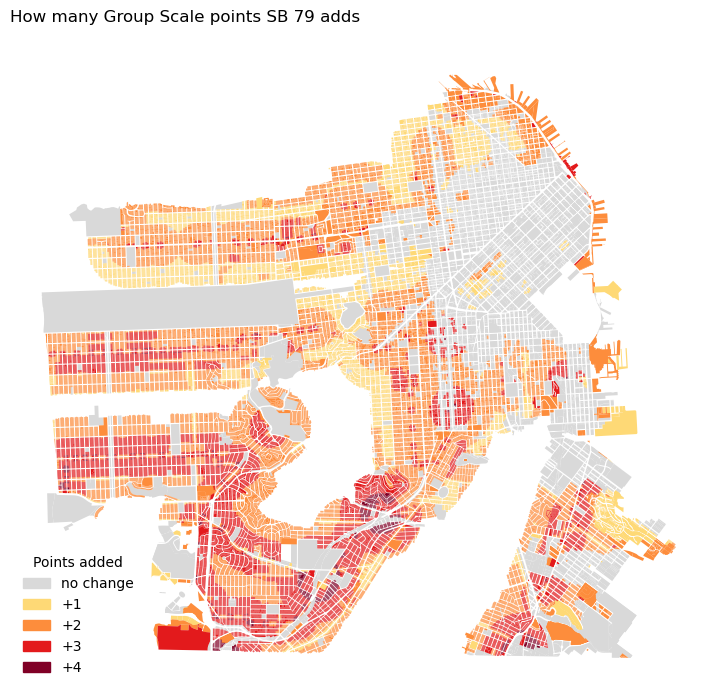

In [5]:
#where does SB 79 raise the scale, and by how many points?
fig, ax = plt.subplots(figsize=(9, 9))
change_colors = {0: "#d9d9d9", 1: "#fed976", 2: "#fd8d3c", 3: "#e31a1c", 4: "#800026", 5: "#4a0014"}
for change, color in change_colors.items():
    layer = sf_sb79_parcels_gdf[sf_sb79_parcels_gdf["scale_change"] == change]
    if len(layer) > 0:
        layer.plot(ax=ax, color=color, linewidth=0)
handles = [plt.matplotlib.patches.Patch(color=c, label=("no change" if k == 0 else f"+{k}")) for k, c in change_colors.items()
           if (sf_sb79_parcels_gdf["scale_change"] == k).any()]
ax.legend(handles=handles, title="Points added", loc="lower left", frameon=False)
ax.set_title("How many Group Scale points SB 79 adds", loc="left")
ax.set_axis_off()
plt.savefig(MAPS_DIR / "sf_scale_change_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
#one shape per block + before score + after score (missing scores become -1 so dissolve keeps them)
web_gdf = sf_sb79_parcels_gdf[["block_num", "scale_before", "scale_after", "acres", "mapblklot", "geometry"]].copy()
web_gdf[["scale_before", "scale_after"]] = web_gdf[["scale_before", "scale_after"]].fillna(-1)
web_gdf = web_gdf.dissolve(
    by=["block_num", "scale_before", "scale_after"],
    aggfunc={"acres": "sum", "mapblklot": "count"},
).reset_index().rename(columns={"mapblklot": "lots"})
web_gdf["geometry"] = web_gdf.simplify(3)
web_gdf["acres"] = web_gdf["acres"].round(2)
print("lots:", len(sf_sb79_parcels_gdf), "-> map shapes:", len(web_gdf))

#text labels so the legend shows our scale names, not just numbers
web_gdf["before"] = web_gdf["scale_before"].map(SCALE_LABELS).fillna("not scored")
web_gdf["after"] = web_gdf["scale_after"].map(SCALE_LABELS).fillna("not scored")
web_gdf = web_gdf.to_crs(4326) #web maps need latitude/longitude

categories = [SCALE_LABELS[s] for s in SCALE_ORDER] + ["not scored"]
colors = [SCALE_COLORS[s] for s in SCALE_ORDER] + [NOT_SCORED_COLOR]
tooltip_columns = ["block_num", "before", "after", "lots", "acres"]

scale_map = web_gdf.explore(
    column="before", categories=categories, cmap=colors,
    tooltip=tooltip_columns, style_kwds={"weight": 0, "fillOpacity": 0.85},
    legend_kwds={"caption": "Group Scale"}, name="Before SB 79",
)
web_gdf.explore(
    m=scale_map, column="after", categories=categories, cmap=colors,
    tooltip=tooltip_columns, style_kwds={"weight": 0, "fillOpacity": 0.85},
    legend=False, name="After SB 79", show=False,
)
folium.LayerControl(collapsed=False).add_to(scale_map)
scale_map.save(MAPS_DIR / "sf_sb79_scale_map.html")
print("saved", MAPS_DIR / "sf_sb79_scale_map.html")

lots: 128637 -> map shapes: 6825
saved ../visualizations/sf_sb79_scale_map.html


In [7]:
def share_by_scale(gdf, column):
    #number of lots and % of acres in each score (missing = not scored)
    counts = gdf.groupby(gdf[column].fillna(-1))["mapblklot"].count()
    acres = gdf.groupby(gdf[column].fillna(-1))["acres"].sum()
    out = pd.DataFrame({"parcels": counts, "acres": acres})
    out["pct_parcels"] = out["parcels"] / out["parcels"].sum() * 100
    out["pct_acres"] = out["acres"] / out["acres"].sum() * 100
    return out.reindex([-1] + SCALE_ORDER, fill_value=0)

before = share_by_scale(sf_sb79_parcels_gdf, "scale_before")
after = share_by_scale(sf_sb79_parcels_gdf, "scale_after")

summary_table = pd.DataFrame({
    "parcels_before": before["parcels"], "parcels_after": after["parcels"],
    "pct_parcels_before": before["pct_parcels"].round(1), "pct_parcels_after": after["pct_parcels"].round(1),
    "acres_before": before["acres"].round(0), "acres_after": after["acres"].round(0),
    "pct_acres_before": before["pct_acres"].round(1), "pct_acres_after": after["pct_acres"].round(1),
})
summary_table.index = ["not scored"] + [SCALE_LABELS[s] for s in SCALE_ORDER]
summary_table.to_csv(MAPS_DIR / "sf_scale_before_after_table.csv")
summary_table

,parcels_before,parcels_after,pct_parcels_before,pct_parcels_after,acres_before,acres_after,pct_acres_before,pct_acres_after
not scored,828,828,0.6,0.6,5032.0,5032.0,23.4,23.4
0 housing not allowed,3055,3055,2.4,2.4,4555.0,4555.0,21.1,21.1
1 under 30 du/ac,50148,0,39.0,0.0,3743.0,0.0,17.4,0.0
2 30-79 du/ac,63964,0,49.7,0.0,5978.0,0.0,27.8,0.0
3 80-99 du/ac,775,44678,0.6,34.7,69.0,3695.0,0.3,17.2
4 100-119 du/ac,2288,64709,1.8,50.3,331.0,5828.0,1.5,27.1
5 120-159 du/ac,794,8558,0.6,6.7,92.0,687.0,0.4,3.2
6 160+ du/ac,6785,6809,5.3,5.3,1736.0,1739.0,8.1,8.1


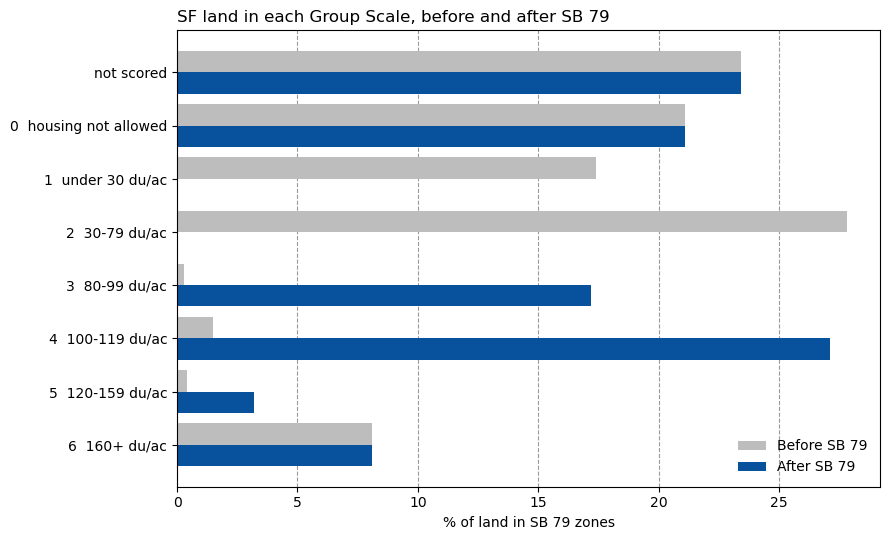

In [8]:
def before_after_chart(column_before, column_after, xlabel, title, filename):
    labels = summary_table.index[::-1] #barh draws the first row at the bottom, so flip to put "not scored" at the top
    y = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(y + 0.2, summary_table[column_before][::-1], height=0.4, color="#bdbdbd", label="Before SB 79")
    ax.barh(y - 0.2, summary_table[column_after][::-1], height=0.4, color="#08519c", label="After SB 79")
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    ax.grid(axis="x", linestyle="--", color="#999999")
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(MAPS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

before_after_chart("pct_acres_before", "pct_acres_after", "% of land in SB 79 zones",
                   "SF land in each Group Scale, before and after SB 79", "sf_pct_acres_before_after.png")

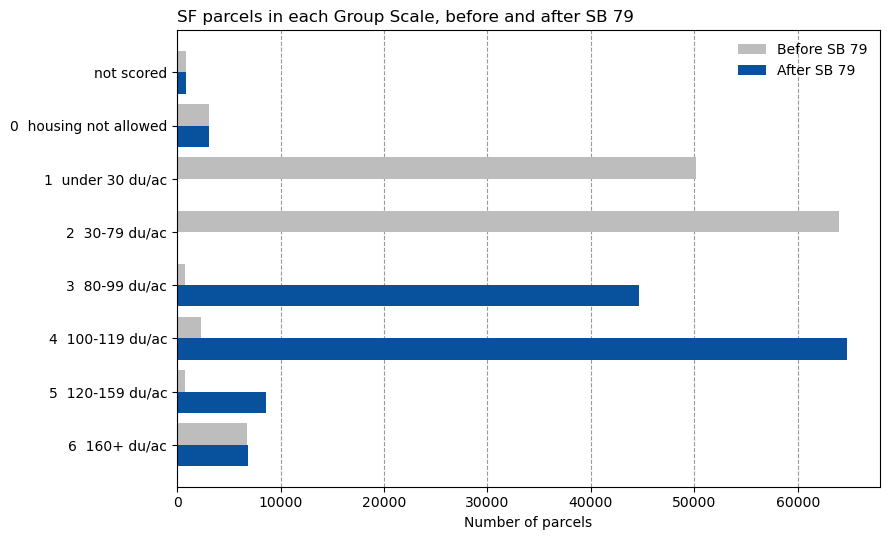

In [9]:
before_after_chart("parcels_before", "parcels_after", "Number of parcels",
                   "SF parcels in each Group Scale, before and after SB 79", "sf_parcels_before_after.png")

In [10]:
#how many lots does SB 79 actually raise?
upzoned = sf_sb79_parcels_gdf["upzoned"]
print(f"lots in SB 79 zones:        {len(sf_sb79_parcels_gdf):,}")
print(f"lots SB 79 raises:          {upzoned.sum():,} ({upzoned.mean():.0%})")
print(f"acres SB 79 raises:         {sf_sb79_parcels_gdf.loc[upzoned, 'acres'].sum():,.0f} of {sf_sb79_parcels_gdf['acres'].sum():,.0f}")
print(f"average points added (raised lots): {sf_sb79_parcels_gdf.loc[upzoned, 'scale_change'].mean():.1f}")

lots in SB 79 zones:        128,637
lots SB 79 raises:          115,099 (89%)
acres SB 79 raises:         9,821 of 21,535
average points added (raised lots): 2.1


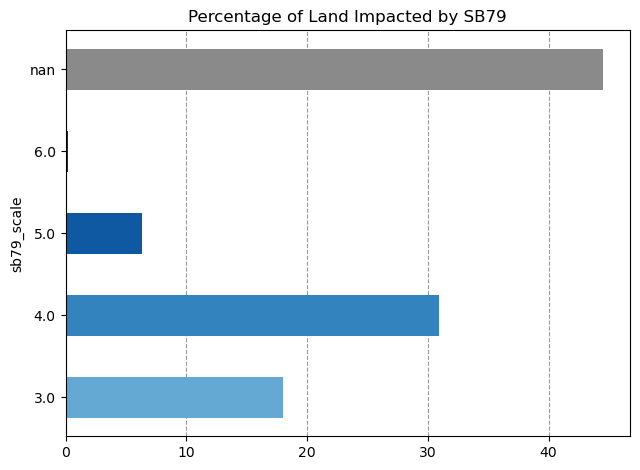

In [11]:
#SB 79 only matters where housing is allowed and the lot is scored, like the Oakland charts
sb79_applies = sf_sb79_parcels_gdf["scale_before"] > 0
sf_sb79_parcels_gdf["sb79_scale_chart"] = sf_sb79_parcels_gdf["sb79_scale"].where(sb79_applies)

def scale_bar_chart(values, title, filename):
    #values: one number per sb79 score (index), with missing last
    values = values.sort_index(na_position="last")
    labels = [("nan" if pd.isna(v) else str(float(v))) for v in values.index]
    colors = [(NOT_SCORED_COLOR if pd.isna(v) else SCALE_COLORS[int(v)]) for v in values.index]
    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    ax.barh(labels, values.values, color=colors, height=0.5)
    ax.set_ylabel("sb79_scale")
    ax.set_title(title)
    ax.grid(axis="x", linestyle="--", color="#999999")
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(MAPS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

land_by_sb79 = sf_sb79_parcels_gdf.groupby("sb79_scale_chart", dropna=False)["acres"].sum()
scale_bar_chart(land_by_sb79 / land_by_sb79.sum() * 100, "Percentage of Land Impacted by SB79", "sf_pct_land_by_sb79_scale.png")

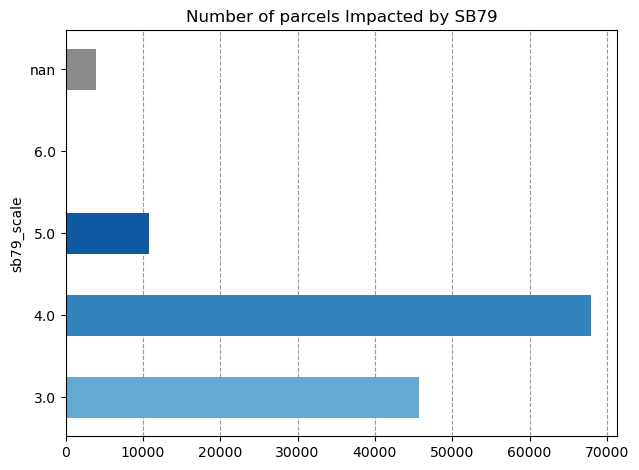

In [12]:
parcels_by_sb79 = sf_sb79_parcels_gdf.groupby("sb79_scale_chart", dropna=False)["mapblklot"].count()
scale_bar_chart(parcels_by_sb79, "Number of parcels Impacted by SB79", "sf_parcels_by_sb79_scale.png")

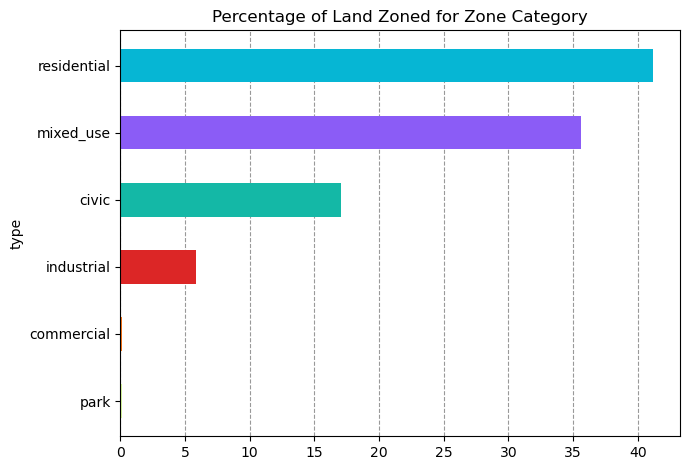

In [13]:
def type_bar_chart(values, title, filename):
    values = values.sort_values() #barh draws the first row at the bottom, so the biggest ends up on top
    fig, ax = plt.subplots(figsize=(7, 4.8))
    ax.barh(values.index, values.values, color=[TYPE_COLORS.get(t, "#9ca3af") for t in values.index], height=0.5)
    ax.set_ylabel("type")
    ax.set_title(title)
    ax.grid(axis="x", linestyle="--", color="#999999")
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(MAPS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

land_by_type = sf_sb79_parcels_gdf.groupby("type")["acres"].sum()
type_bar_chart(land_by_type / land_by_type.sum() * 100, "Percentage of Land Zoned for Zone Category", "sf_pct_land_by_type.png")

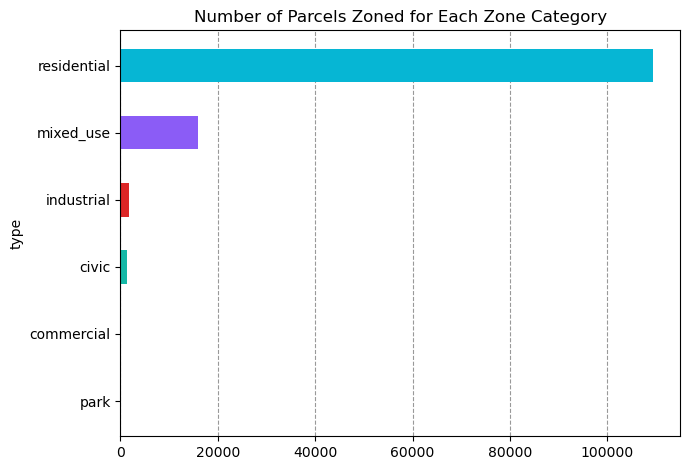

In [14]:
parcels_by_type = sf_sb79_parcels_gdf.groupby("type")["mapblklot"].count()
type_bar_chart(parcels_by_type, "Number of Parcels Zoned for Each Zone Category", "sf_parcels_by_type.png")